# Logistic Regression — From First Principles

**Goal:** understand logistic regression as a probabilistic linear classifier; derive its loss and gradient; implement binary logistic regression with NumPy; compare against scikit-learn; and consider scaling and GPU execution.

This notebook focuses on **binary logistic regression**. Multiclass softmax regression is introduced near the end. Ridge, Lasso, and Elastic Net are different regularized objectives and should get their own focused sections.

## 1. Definition and intuition

Logistic regression predicts the probability that an observation belongs to a class. Despite its name, it is a classification model.

For input features \(x\), it first computes a linear score \(z=w^T x+b\), then maps that score to a number between zero and one using the sigmoid:

\[\sigma(z)=\frac{1}{1+e^{-z}}.\]

The result \(p(y=1\mid x)=\sigma(w^Tx+b)\) is interpreted as the positive-class probability. A threshold (often 0.5) converts probability to a class label, but that threshold is a decision choice rather than a property the model must use.

## 2. Mathematical foundation: Bernoulli likelihood

For each label \(y_i\in\{0,1\}\), the Bernoulli model gives

\[P(y_i\mid x_i)=p_i^{y_i}(1-p_i)^{1-y_i},\quad p_i=\sigma(w^Tx_i+b).\]

Assuming samples are conditionally independent, the likelihood is the product of these terms. Maximizing likelihood is equivalent to minimizing the **negative log-likelihood**, also called binary cross-entropy:

\[J(w,b)=-\frac1n\sum_{i=1}^n [y_i\log p_i+(1-y_i)\log(1-p_i)].\]

For L2 regularization, add \(\frac{\lambda}{2}\|w\|_2^2\) (here the intercept is not penalized). The gradient is

\[\nabla_w J=\frac1n X^T(p-y)+\lambda w,\qquad \frac{\partial J}{\partial b}=\frac1n\sum_i(p_i-y_i).\]

These gradients follow from the sigmoid derivative \(\sigma'(z)=\sigma(z)(1-\sigma(z))\). The chain rule simplifies the derivative of cross-entropy with respect to each score to \(p_i-y_i\).

## 3. Why optimization works — and what is guaranteed

For binary logistic regression, the negative log-likelihood is convex in the linear parameters. Its Hessian has the form

\[\nabla^2 J=\frac1n X^T W X+\lambda I,\]

where \(W\) is diagonal with entries \(p_i(1-p_i)\geq0\), and the regularization term applies to weights, not the intercept. Therefore the unregularized Hessian is positive semidefinite; adding positive L2 regularization makes the weight-direction curvature better behaved. Under suitable rank and regularization conditions the optimum is unique.

Gradient descent can converge to a global minimizer when its step size and stopping conditions are suitable for the objective. This does **not** mean that every arbitrary learning rate converges, that the finite-sample model is well-calibrated, or that it predicts unseen data accurately. Perfectly separable data can also cause unregularized coefficients to grow without reaching a finite maximum-likelihood estimate.

## 4. Assumptions and common failure modes

- The log-odds are linear in the supplied features; interactions or nonlinear terms may be needed otherwise.
- Observations should be independent for the usual likelihood interpretation; grouped or time-dependent data may need different validation schemes.
- Strongly correlated features can make coefficients hard to interpret.
- Severe class imbalance can make accuracy misleading. Inspect precision, recall, PR-AUC, and the confusion matrix.
- Probabilities depend on the modeling assumptions and data distribution; evaluate calibration when probability quality matters.
- Feature scaling usually improves the conditioning of gradient-based optimization and is essential for comparing regularization strength across features.

Logistic regression does not require the features themselves to be normally distributed.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
print("NumPy ready")

NumPy ready


## 5. Toy dataset and the train/test boundary

We generate a two-feature binary dataset so the decision boundary can be visualized. The split is performed **before** fitting the scaler. Fitting preprocessing on all observations would leak test-set information into training.

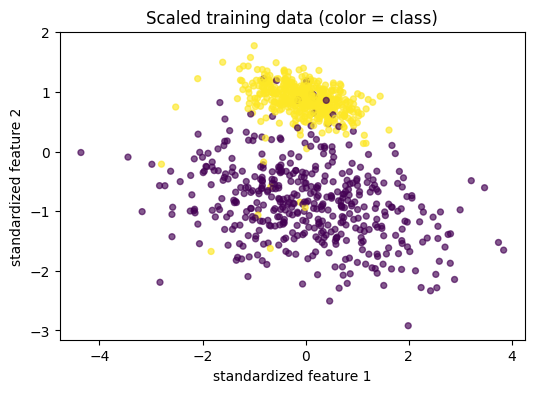

In [2]:
X, y = make_classification(
    n_samples=1200, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.25, flip_y=0.04, random_state=SEED
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

plt.figure(figsize=(6, 4))
plt.scatter(X_train_s[:, 0], X_train_s[:, 1], c=y_train, s=18, alpha=0.65)
plt.title("Scaled training data (color = class)")
plt.xlabel("standardized feature 1"); plt.ylabel("standardized feature 2"); plt.show()

## 6. Implement stable binary logistic regression with NumPy

Numerical stability matters. Instead of evaluating \(\log(1+e^z)\) directly, use `np.logaddexp(0, z)`, a stable implementation of the softplus function. We minimize

\[J=\operatorname{mean}(\operatorname{softplus}(z)-yz)+\frac{\lambda}{2}\|w\|^2.\]

This form is algebraically equivalent to binary cross-entropy and avoids taking the logarithm of probabilities that have rounded to exactly zero.

In [3]:
class LogisticRegressionGD:
    """Educational full-batch binary logistic regression using NumPy."""
    def __init__(self, learning_rate=0.1, max_iter=10_000, l2=0.0, tol=1e-8):
        if learning_rate <= 0 or max_iter < 1 or l2 < 0 or tol < 0:
            raise ValueError("learning_rate/max_iter must be positive; l2/tol nonnegative")
        self.learning_rate = float(learning_rate)
        self.max_iter = int(max_iter)
        self.l2 = float(l2)
        self.tol = float(tol)

    @staticmethod
    def _sigmoid(z):
        # Clipping prevents exp overflow while retaining adequate precision for this demo.
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def _loss(self, X, y, w, b):
        z = X @ w + b
        return float(np.mean(np.logaddexp(0.0, z) - y * z) + 0.5 * self.l2 * (w @ w))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
            raise ValueError("X must be a non-empty 2D array")
        if y.ndim != 1 or len(y) != len(X):
            raise ValueError("y must be 1D with one label per row")
        if not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError("X and y must contain only finite values")
        labels = np.unique(y)
        if not np.array_equal(labels, np.array([0.0, 1.0])):
            raise ValueError("This implementation expects binary labels encoded as 0 and 1")

        n, d = X.shape
        self.coef_ = np.zeros(d, dtype=float)
        self.intercept_ = 0.0
        self.loss_history_ = []
        for _ in range(self.max_iter):
            p = self._sigmoid(X @ self.coef_ + self.intercept_)
            grad_w = (X.T @ (p - y)) / n + self.l2 * self.coef_
            grad_b = float(np.mean(p - y))
            grad_norm = np.sqrt(grad_w @ grad_w + grad_b * grad_b)
            self.coef_ -= self.learning_rate * grad_w
            self.intercept_ -= self.learning_rate * grad_b
            self.loss_history_.append(self._loss(X, y, self.coef_, self.intercept_))
            if grad_norm <= self.tol:
                break
        self.n_iter_ = len(self.loss_history_)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != len(self.coef_):
            raise ValueError("X must be 2D with the same feature count used during fit")
        p1 = self._sigmoid(X @ self.coef_ + self.intercept_)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X, threshold=0.5):
        if not 0 < threshold < 1:
            raise ValueError("threshold must be strictly between 0 and 1")
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

model = LogisticRegressionGD(learning_rate=0.1, max_iter=10_000, l2=0.01, tol=1e-7)
model.fit(X_train_s, y_train)
proba = model.predict_proba(X_test_s)[:, 1]
pred = model.predict(X_test_s)
print("iterations:", model.n_iter_)
print("test accuracy:", round(accuracy_score(y_test, pred), 4))
print("test log loss:", round(log_loss(y_test, proba), 4))

iterations: 3490
test accuracy: 0.9767
test log loss: 0.144


## 7. Visualize the learned decision boundary and loss

The line where \(p=0.5\) corresponds to \(w^Tx+b=0\). Moving the probability threshold changes the predicted class region without changing the fitted coefficients.

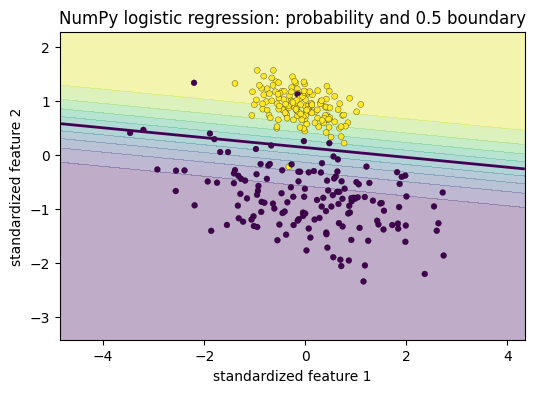

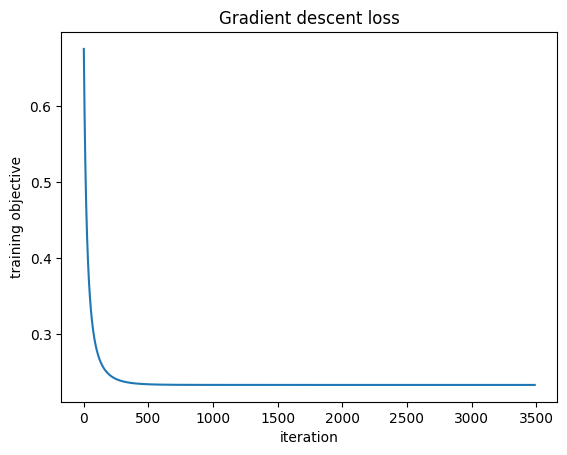

In [4]:
xx, yy = np.meshgrid(
    np.linspace(X_train_s[:, 0].min() - 0.5, X_train_s[:, 0].max() + 0.5, 180),
    np.linspace(X_train_s[:, 1].min() - 0.5, X_train_s[:, 1].max() + 0.5, 180)
)
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict_proba(grid)[:, 1].reshape(xx.shape)
plt.figure(figsize=(6, 4))
plt.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), alpha=0.35)
plt.contour(xx, yy, zz, levels=[0.5], linewidths=2)
plt.scatter(X_test_s[:, 0], X_test_s[:, 1], c=y_test, s=18, edgecolors="k", linewidths=0.2)
plt.title("NumPy logistic regression: probability and 0.5 boundary")
plt.xlabel("standardized feature 1"); plt.ylabel("standardized feature 2"); plt.show()
plt.plot(model.loss_history_)
plt.xlabel("iteration"); plt.ylabel("training objective"); plt.title("Gradient descent loss"); plt.show()

## 8. Compare with scikit-learn

The library uses a mature numerical solver. We compare predictive metrics rather than expecting parameters to be identical: solvers, stopping rules, and regularization conventions differ. Here we use a large `C` to make regularization weak, while our NumPy example uses a small L2 penalty.

In [5]:
sk_model = LogisticRegression(C=100.0, max_iter=2000, solver="lbfgs", random_state=SEED)
sk_model.fit(X_train_s, y_train)
sk_proba = sk_model.predict_proba(X_test_s)[:, 1]
sk_pred = sk_model.predict(X_test_s)
print("NumPy accuracy:", round(accuracy_score(y_test, pred), 4))
print("sklearn accuracy:", round(accuracy_score(y_test, sk_pred), 4))
print("NumPy ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("sklearn ROC-AUC:", round(roc_auc_score(y_test, sk_proba), 4))
print("sklearn confusion matrix:\n", confusion_matrix(y_test, sk_pred))
print(classification_report(y_test, sk_pred, digits=3))
assert accuracy_score(y_test, pred) > 0.75
assert accuracy_score(y_test, sk_pred) > 0.75
assert np.isfinite(proba).all()

NumPy accuracy: 0.9767
sklearn accuracy: 0.98
NumPy ROC-AUC: 0.9887
sklearn ROC-AUC: 0.9888
sklearn confusion matrix:
 [[145   5]
 [  1 149]]
              precision    recall  f1-score   support

           0      0.993     0.967     0.980       150
           1      0.968     0.993     0.980       150

    accuracy                          0.980       300
   macro avg      0.980     0.980     0.980       300
weighted avg      0.980     0.980     0.980       300



## 9. Multiclass extension: softmax regression

For \(K\) classes, compute one score per class, \(s=XW+b\), and convert scores to probabilities with softmax:

\[p_{ik}=\frac{e^{s_{ik}}}{\sum_{j=1}^K e^{s_{ij}}}.\]

The multiclass cross-entropy objective is \(-\frac1n\sum_i\log p_{i,y_i}\). For numerical stability, subtract the maximum score in each row before exponentiating. scikit-learn's `LogisticRegression` supports multiclass problems; its internal formulation/solver behavior depends on configuration and version.

In [6]:
def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    shifted = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(shifted)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)

example_scores = np.array([[2.0, 1.0, 0.1], [0.2, 0.2, 0.2]])
example_probs = softmax(example_scores)
print(example_probs)
assert np.allclose(example_probs.sum(axis=1), 1.0)
assert np.all((example_probs >= 0) & (example_probs <= 1))

[[0.65900114 0.24243297 0.09856589]
 [0.33333333 0.33333333 0.33333333]]


## 10. Hyperparameters and best practices

| Parameter / choice | Meaning and trade-off |
|---|---|
| `learning_rate` | Step size for gradient descent. Too large can diverge; too small trains slowly. |
| `max_iter` | Maximum gradient updates; check convergence rather than blindly raising it. |
| `l2` | Penalty strength in this educational implementation. Larger values shrink coefficients more. |
| `tol` | Gradient-norm stopping threshold here; other libraries may define tolerance differently. |
| classification threshold | Controls precision/recall trade-off; select it on validation data for the actual objective. |
| feature scaling | Fit the scaler on the training split only; use pipelines in real workflows. |

Use `Pipeline(StandardScaler(), LogisticRegression(...))` in scikit-learn to avoid leakage. Evaluate with metrics suitable for the task, inspect calibration if probabilities matter, and check convergence warnings.

## 11. Time and space complexity

Let \(n\) be training rows, \(d\) features, \(T\) full-batch iterations, and \(m\) inference rows.

| Operation | Typical dense complexity |
|---|---|
| One gradient-descent iteration | Time \(O(nd)\); temporary storage \(O(n+d)\) beyond the input matrix |
| Training for \(T\) iterations | Time \(O(Tnd)\); stored input \(O(nd)\), model \(O(d)\) |
| Binary batch inference | Time \(O(md)\); model storage \(O(d)\) |
| Softmax inference with \(K\) classes | Time \(O(mdK)\); model storage \(O(dK)\) |

These figures assume dense features and full-batch gradient descent. Solver complexity differs; sparse text data can be much more efficient with a sparse-aware estimator.

## 12. Scaling to millions of samples

- Keep features sparse when possible; do not convert a high-dimensional sparse text matrix to dense form.
- Standardize appropriately and choose a solver designed for dataset size and sparsity.
- `SGDClassifier(loss="log_loss")` supports stochastic/minibatch-style optimization and `partial_fit` workflows.
- Track validation metrics, convergence, and training wall time; choose the decision threshold separately when needed.
- Batch inference to bound memory when serving a very large dataset.
- Benchmark on the target hardware rather than inferring speed from asymptotic complexity alone.

In [7]:
from sklearn.linear_model import SGDClassifier

# A scalable-library example. This is not the same optimization trajectory as full-batch GD.
sgd = SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=2000, tol=1e-4, random_state=SEED)
sgd.fit(X_train_s, y_train)
print("SGDClassifier test accuracy:", round(accuracy_score(y_test, sgd.predict(X_test_s)), 4))

# Small benchmark helper; increase n gradually on your own machine.
def benchmark_logistic(n_samples, n_features=20, seed=0):
    Xb, yb = make_classification(n_samples=n_samples, n_features=n_features,
                                 n_informative=min(10, n_features), n_redundant=0,
                                 random_state=seed)
    start = time.perf_counter()
    clf = LogisticRegression(max_iter=500, solver="lbfgs").fit(Xb, yb)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter(); clf.predict(Xb[: min(10_000, n_samples)])
    predict_seconds = time.perf_counter() - start
    return {"n": n_samples, "d": n_features, "fit_seconds": round(fit_seconds, 3),
            "predict_seconds_for_up_to_10k": round(predict_seconds, 4)}

[benchmark_logistic(n) for n in (1_000, 10_000, 50_000)]

SGDClassifier test accuracy: 0.97


[{'n': 1000,
  'd': 20,
  'fit_seconds': 0.002,
  'predict_seconds_for_up_to_10k': 0.0001},
 {'n': 10000,
  'd': 20,
  'fit_seconds': 0.006,
  'predict_seconds_for_up_to_10k': 0.0002},
 {'n': 50000,
  'd': 20,
  'fit_seconds': 0.148,
  'predict_seconds_for_up_to_10k': 0.0004}]

## 13. GPU option with PyTorch

Logistic regression consists mostly of dense linear algebra and can run on a GPU. For small data, transferring data to the GPU can cost more than the computation. This example selects CUDA when available and otherwise runs on CPU. PyTorch is an optional dependency for this section.

In [8]:
try:
    import torch
    from torch import nn

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    X_t = torch.tensor(X_train_s, dtype=torch.float32, device=device)
    y_t = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32, device=device)
    torch_model = nn.Linear(X_t.shape[1], 1).to(device)
    optimizer = torch.optim.SGD(torch_model.parameters(), lr=0.1)
    criterion = nn.BCEWithLogitsLoss()
    for _ in range(1000):
        optimizer.zero_grad()
        logits = torch_model(X_t)
        loss = criterion(logits, y_t)
        loss.backward()
        optimizer.step()
    print("PyTorch device:", device, "final loss:", float(loss.detach().cpu()))
except ImportError:
    print("PyTorch is not installed; skip this optional GPU section.")

PyTorch device: cpu final loss: 0.1681278795003891


## 14. Correctness checks and synthesis

The mental model: logistic regression assumes the **log-odds** are a linear function of the features. Training selects coefficients that make the observed labels likely, using a convex cross-entropy objective. The sigmoid maps scores to probabilities; a threshold converts those probabilities into decisions.

Before using the model, verify input shapes, check convergence, avoid preprocessing leakage, evaluate class-appropriate metrics, and compare against a simple baseline.

In [9]:
# Input validation, probability sanity, and deterministic-fit checks
assert model.predict_proba(X_test_s).shape == (len(X_test_s), 2)
assert np.allclose(model.predict_proba(X_test_s).sum(axis=1), 1.0)
assert np.isfinite(model.coef_).all() and np.isfinite(model.intercept_)
model2 = LogisticRegressionGD(learning_rate=0.1, max_iter=10_000, l2=0.01, tol=1e-7)
model2.fit(X_train_s, y_train)
assert np.allclose(model.coef_, model2.coef_) and np.isclose(model.intercept_, model2.intercept_)
try:
    LogisticRegressionGD().fit(np.array([1, 2, 3]), np.array([0, 1, 0]))
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid-shape error")
print("All logistic-regression checks passed.")

All logistic-regression checks passed.
